In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv(r"C:\Users\jmanu\pythondecalfa\course_assignments\homework9\solar_system.csv")
print(df)

                      Attribute Mercury    Venus  Earth   Moon   Mars  \
0                Mass (10^24kg)   0.330     4.87   5.97  0.073  0.642   
1                 Diameter (km)    4879    12104  12756   3475   6792   
2              Density (kg/m^3)    5429     5243   5514   3340   3934   
3               Gravity (m/s^2)     3.7      8.9    9.8    1.6    3.7   
4        Escape Velocity (km/s)     4.3     10.4   11.2    2.4    5.0   
5       Rotation Period (hours)  1407.6  -5832.5   23.9  655.7   24.6   
6         Length of Day (hours)  4222.6   2802.0   24.0  708.7   24.7   
7   Distance from Sun (10^6 km)    57.9    108.2  149.6  0.384  228.0   
8          Perihelion (10^6 km)    46.0    107.5  147.1  0.363  206.7   
9            Aphelion (10^6 km)    69.8    108.9  152.1  0.406  249.3   
10        Orbital Period (days)    88.0    224.7  365.2   27.3  687.0   
11      Orbital Velocity (km/s)    47.4     35.0   29.8    1.0   24.1   
12    Orbital Inclination (deg)     7.0      3.4   

In [4]:
df.shape
# 20 rows, 11 columns

(20, 11)

In [5]:
df.head()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3


In [6]:
df.tail()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
15,Mean Temperature (C),167,464,15,-20,-65,-110,-140,-195,-200,-225
16,Surface Pressure (bars),0,92,1,0,0.01,Unknown,Unknown,Unknown,Unknown,0.00001
17,Number of Moons,0,0,1,0,2,95,274,28,16,5
18,Ring System?,No,No,No,No,No,Yes,Yes,Yes,Yes,No
19,Global Magnetic Field?,Yes,No,Yes,No,No,Yes,Yes,Yes,Yes,Unknown


In [8]:
print(df.columns)
# Attribute, Mercury, Venus, Earth, Moon, Mars, Jupiter, Saturn, Uranus, Neptune, Pluto

Index(['Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter',
       'Saturn', 'Uranus', 'Neptune', 'Pluto'],
      dtype='str')


In [11]:
print(df.index)

RangeIndex(start=0, stop=20, step=1)


In [13]:
orbital_period = df.iloc[10, 1:].astype(float)
print(orbital_period)

perihelion = df.iloc[8, 1:].astype(float)
print(perihelion)

aphelion = df.iloc[9, 1:].astype(float)
print(aphelion)

Mercury       88.0
Venus        224.7
Earth        365.2
Moon          27.3
Mars         687.0
Jupiter     4331.0
Saturn     10747.0
Uranus     30589.0
Neptune    59800.0
Pluto      90560.0
Name: 10, dtype: float64
Mercury      46.000
Venus       107.500
Earth       147.100
Moon          0.363
Mars        206.700
Jupiter     740.600
Saturn     1357.600
Uranus     2732.700
Neptune    4471.100
Pluto      4436.800
Name: 8, dtype: float64
Mercury      69.800
Venus       108.900
Earth       152.100
Moon          0.406
Mars        249.300
Jupiter     816.400
Saturn     1506.500
Uranus     3001.400
Neptune    4558.900
Pluto      7375.900
Name: 9, dtype: float64


In [14]:
# 1. Perihelion: The point where a planet is at its closest distance from the sun during its orbit 
# 2. Aphelion: The point where a planet is at its furthest distance from the sun during its orbit
# 3. Semi-major axis: Half of the longest diameter of a planet's elliptical orbit

In [16]:
semi_major_axis = (perihelion + aphelion) / 2

semi_major_row = pd.Series(
    ['Semi-Major Axis (10^6 km)'] + semi_major_axis.tolist(), index=df.columns
)

df = pd.concat([df, semi_major_row.to_frame().T], ignore_index=True)

print(df.shape)
# 21 rows, 11 columns

(21, 11)


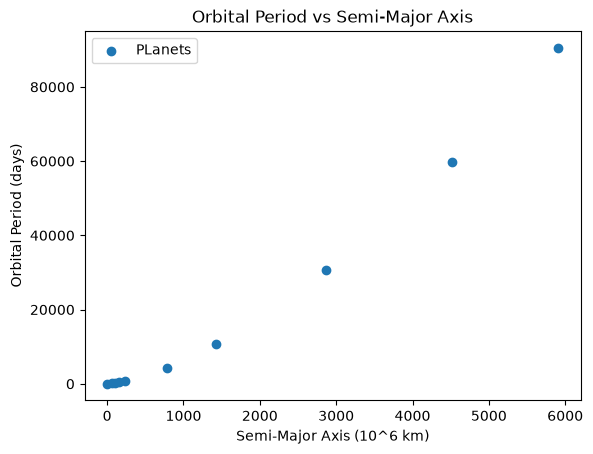

In [17]:
plt.scatter(semi_major_axis, orbital_period, label = 'PLanets')

plt.xlabel('Semi-Major Axis (10^6 km)')
plt.ylabel('Orbital Period (days)')
plt.title('Orbital Period vs Semi-Major Axis')
plt.legend()

plt.show()

In [18]:
def keplers_third_law(a, m):
    return m * (a ** 1.5)

popt, pcov = curve_fit(keplers_third_law, semi_major_axis, orbital_period)

m_fit = popt[0]

print(m_fit)

0.19879981918623565


In [19]:
print(f"Orbital Period = {m_fit:.2f} * a^1.5")

Orbital Period = 0.20 * a^1.5


In [21]:
model_values = keplers_third_law(semi_major_axis, m_fit)

residuals = orbital_period - model_values

chi2 = sum(residuals**2)

dof = len(orbital_period) - 1

chi2_reduced = chi2 / dof